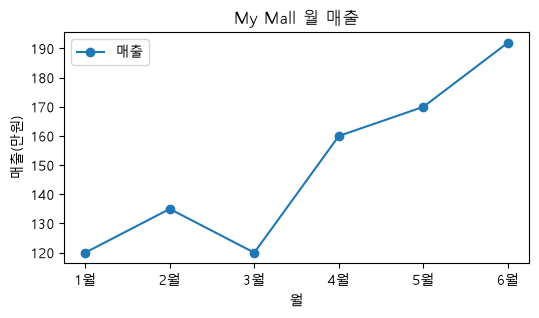

In [ ]:
import numpy as np
import pandas as pd

# 통계 그래프 라이브러리 seaborn
import seaborn as sns
# matplotlib.pyplot : 그래프 생성하고 설정하는 라이브러리 모듈
import matplotlib.pyplot as plt

# 한글 폰트 설정
# Windows OS
plt.rcParams["font.family"] = "Malgun Gothic"       
# 맥 OS : plt.rcParams["font.family"] = "AppleGothic"

# Figure(캔버스), Axes(그래프)
fig, ax = plt.subplots(figsize=(6, 3))
# X축 데이터 (월)
months = ["1월", "2월", "3월","4월","5월","6월"]
# Y축 데이터 (매출액, 만원)
sales = [120, 135, 120, 160, 170, 192]


# 내가 선그래프와 비교하려고 가저온 히스토그램
# ax.hist(df["age"], bins=20, color="blue", edgecolor="black") 
# ax.set_title("나이분포")
# ax.set_xlabel("나이(세)")


# 선그래프 
ax.plot(months, sales, marker="o", label="매출")

ax.set_title("My Mall 월 매출")
ax.set_xlabel("월")
ax.set_ylabel("매출(만원)")

# 범례 표시
ax.legend();
# 차트 그리기
plt.show()

In [2]:
import pandas as pd

# csv를 불러옴
house = pd.read_csv("./datasets/usa_housing.csv")

print(house.shape)
house

(300, 10)


,Price,Bedrooms,Bathrooms,SquareFeet,YearBuilt,GarageSpaces,LotSize,ZipCode,CrimeRate,SchoolRating
0,221958,1,1.9,4827,1979,2,1.45,82240,48.60,5
1,771155,2,2.0,1035,1987,2,1.75,74315,92.03,9
2,231932,1,3.0,2769,1982,1,1.46,79249,52.08,3
3,465838,3,3.3,2708,1907,3,1.62,80587,61.65,1
4,359178,4,3.4,1175,1994,2,0.74,20756,15.66,4
...,...,...,...,...,...,...,...,...,...,...
295,862002,4,2.8,1129,1944,0,1.80,35227,32.30,3
296,242483,3,2.4,4440,1988,2,0.46,15978,99.71,9
297,758271,2,2.2,4694,1952,2,0.71,97527,97.98,7
298,314835,5,2.0,4907,1941,3,0.53,27153,65.61,8


In [3]:
small = house[(house["YearBuilt"] > 2015) & (house["CrimeRate"] < 40)]
small.shape

(10, 10)

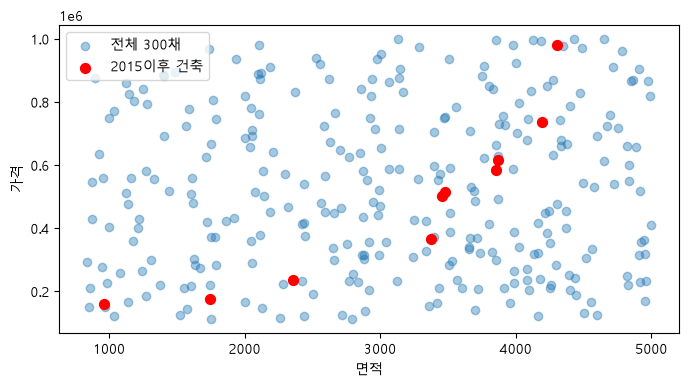

전체 300채의 상관계수: 0.08
10채의 상관계수: 0.89


In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))

plt.scatter(house["SquareFeet"], house["Price"], alpha=0.4, label="전체 300채")

plt.scatter(small["SquareFeet"], small["Price"], color="red", s=50, label="2015이후 건축")

plt.xlabel("면적")

plt.ylabel("가격")

plt.legend()

plt.show()

# corr 상관계수구하는 함수 상관계수 1에 가까울수록 상관관계가 높음
print("전체 300채의 상관계수:", round(house["SquareFeet"].corr(house["Price"]),2))
print("10채의 상관계수:", round(small["SquareFeet"].corr(small["Price"]),2))

In [ ]:
# 시드 (seed) : 난수 발생시 참고하는 데이터, 동일한 seed 값을 적용하는 항상 동일한 난수가 발생
# default_rng(x) : NumPy의 난수 생성기를 만드는 함수 시드만 같으면 나오는 값이 같음
rng = np.random.default_rng(40)

n = 200

# 20 이상 85 미만에서 균등하게 n개만큼 난수 발생
area = rng.uniform(20, 85, n)
# y = wx + b / x : area / w : 기울기 450 / b : 편향(절편) 5000
price = (area * 450 + 5000 + (rng.normal(0 ,2500, n))).round(-1) # < 이 코드는 왜 round가 뒤에 있는지

# 특이 매물 5건 생성
# replace=False 같은 번호를 중복해서 뽑지 않는다
special = rng.choice(n, 5, replace=False)
price[special] += rng.uniform(15000, 25000, 5).round(-1)

office = pd.DataFrame({"area": area, "price" : price})

office.describe().round(1)

,area,price
count,200.0,200.0
mean,52.8,29138.4
std,18.6,9112.1
min,22.0,11400.0
25%,37.4,21615.0
50%,52.0,28965.0
75%,67.4,36377.5
max,84.9,58460.0


In [ ]:
# 파일 저장
# 인덱스 번호를 제외하고 저장
office.to_csv("./datasets/office.csv", index=False)



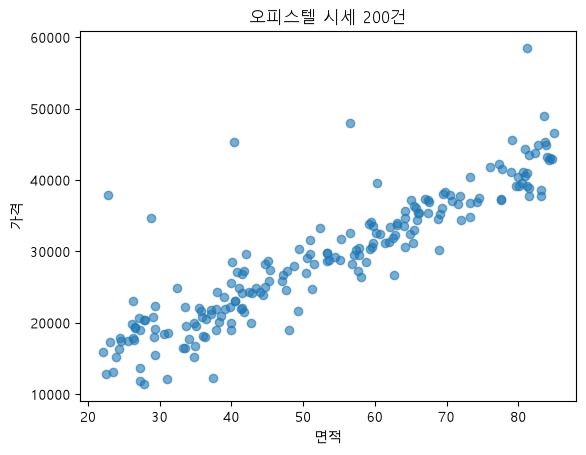

상관계수: 0.8963336215680755


In [7]:
# 산점도 차트

# 캔버스 (Figure) 생성
plt.Figure(figsize=(8,5))

# 산점도 차트
plt.scatter(office["area"], office["price"], alpha=0.6)

# 타이틀 x y 레이블
plt.title("오피스텔 시세 200건")

plt.xlabel("면적")

plt.ylabel("가격")

plt.show()

print("상관계수:", office["area"].corr(office["price"]))
# 상관계수: 0.8963336215680755  > 상관계수가 높다고 ~~ 되는게 아님

In [ ]:
# LinearRegression : 수치를 예측하는 직선형 회귀 모델
from sklearn.linear_model import LinearRegression

X = office[["area"]]
Y = office["price"]

# 선형 회귀(최적의 직선값) 모델 만들기
model = LinearRegression()

# 학습 : X(입력) , y(정답)
model.fit(X,Y)

# 
print(f"기울기 w {model.coef_[0]} 정답: 450")
print(f"절편 b {model.intercept_} 정답: 5000")

기울기 w 439.45870417134705 정답: 450
절편 b 5926.680580056112 정답: 5000


In [9]:
# 33, 59 가격 예측

new = pd.DataFrame({"area" : [33, 59]})

# predict :
model.predict(new).round(-1)

array([20430., 31850.])

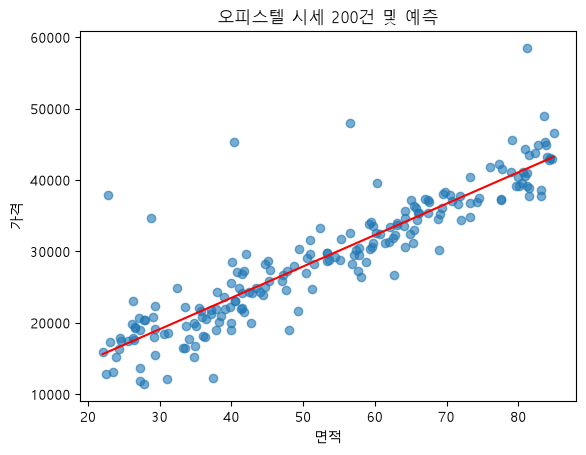

In [10]:
# 학습한 모델로 예측하기

y_pred = model.predict(X)

line = X.sort_values("area")

line_pred = model.predict(line)


plt.Figure(figsize=(8,5))
plt.scatter(office["area"], office["price"], alpha=0.6)

# 모델의 직선
plt.plot(line["area"], line_pred, color="red", label="모델의 직선")

plt.title("오피스텔 시세 200건 및 예측")
plt.xlabel("면적")
plt.ylabel("가격")
plt.show()

In [ ]:
# 회귀 모델 성능 평가 지표 4가지

# MAE : 오차에 절댓값을 씌운 후 평균 계산
# MSE : 오차를 제곱한 후 평균 계산
# RMSE : MSE에 제곱근(루트)을 적용
# R² : 모델이 실제 데이터의 변동을 얼마나 설명하는지 나타내는 결정계수

In [ ]:
# MAE, MSE, RMSE, R_SCORE
# sklearn.metrics : 머신러닝 모델의 성능을 평가하는 모듈
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score

# MAE : 오차 절댓값의 평균 -> 평균적으로 얼마만큼 틀리나?
print(f"MAE = {mean_absolute_error(Y, y_pred):,.0f}")
# MSE: 오차 제곱의 평균 (단위 제곱)
print(f"MSE = {mean_squared_error(Y, y_pred):,.0f}")
# RMSE: 오차 제곱 평균의 루트
print(f"RMSE = {root_mean_squared_error(Y, y_pred):,.0f}")
# R_SCORE : -1 ~ 1
print(f"R_SCORE = {r2_score(Y, y_pred):.3f}")




MAE = 2,493
MSE = 16,240,971
RMSE = 4,030
R_SCORE = 0.803


In [ ]:
# np.ones() : 지정한 크기만큼 1로 채워진 배열 생성
# dtype=bool : 자료형을 bool로 지정
normal = np.ones(len(office), dtype=bool)

# 특이 매물에 해당하는 위치의 값을 False로 변경
normal[special] = False

print("특이매물", special)
print("정상매물", normal.sum())

특이매물 [53 13  2 92 71]
정상매물 195


In [27]:
all_rows = np.ones(len(office), dtype=bool)
cases = [("전체 200건", all_rows), ("특이매물 제외 195건", normal)]

for name, mask in cases:
    # 실제가격
    y_true = Y[mask]
    
    # 예측가격
    y_hat = y_pred[mask]        

    # MAE : 오차 절대값의 평균
    mae = mean_absolute_error(y_true, y_hat)
    # RMSE
    rmse = root_mean_squared_error(y_true, y_hat)

    # R2
    r2 = r2_score(y_true, y_hat)

    print(f"{name} MAE{mae} | RMSE {rmse} | RScore{r2}")

전체 200건 MAE2492.503948887723 | RMSE 4030.0088601264406 | RScore0.8034139611533421
특이매물 제외 195건 MAE2075.1039768452683 | RMSE 2731.5353914457346 | RScore0.9023854405903358
